# 02. Can we trust the experiment, and how big is the effect?

**The question this notebook answers:** was the experiment run the way it was designed, and once
we trust (or correct) the data, how many more users visited because of the campaign? Then:
should we ship, not ship, or run longer?

Four checks, in order: **sample ratio mismatch** (did the arms come out the right size?),
**balance** (can a model tell treated users from control users?), the **lift itself** (raw and
adjusted, with confidence intervals), and **how the decision changes** with the practical
threshold we pick.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2, norm

from expkit import config, nb
from expkit.decision import decide, required_scale
from expkit.inference import EffectEstimate
from expkit.report import ci_pp, n_, pct, pp, scale_text
from expkit.srm import srm_test

ctx = nb.load()
R = ctx.results
design, effect = R["design"], R["effect"]
ctx.banner()

> Data: **Criteo Uplift v2.1**. Pipeline numbers are read from `docs/results/results.json` (written by `expkit run-all` at code commit `41db89a`) and match `docs/RESULTS.md`. Seed 42.

## 1. Sample ratio mismatch (SRM)

The experiment was designed to put about 85% of users in the campaign and 15% in control. If a
logging bug, a bot filter or a broken randomizer dropped users unevenly, the counts would drift
from that ratio and the comparison could no longer be trusted. The check is a chi-square test
of the observed counts against the designed ratio. The team that runs it sets a strict alarm
level (here p < 0.001) so that it only fires on real problems.

- Check: SRM p-value: recomputed `0.998924`, pipeline `0.998924` (matches)

,designed share,expected users,observed users,observed share
control,15.00%,"2,096,939","2,096,937",15.0000%
treatment,85.00%,"11,882,653","11,882,655",85.0000%


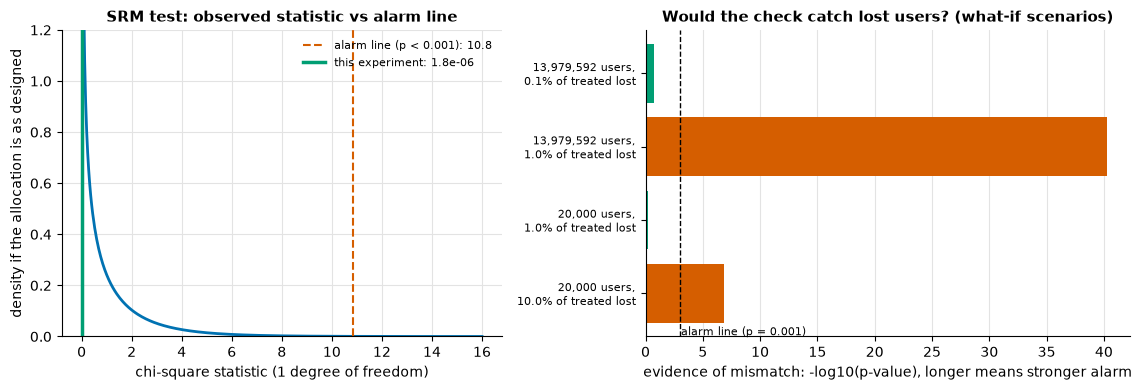

In [2]:
obs = design["srm"]["observed"]
srm = srm_test(obs, config.DESIGN_RATIO_CONTROL_TREATMENT)
ctx.check("SRM p-value", srm.p_value, design["srm"]["p_value"], rtol=1e-6)

srm_table = pd.DataFrame(
    {
        "designed share": [pct(0.15), pct(0.85)],
        "expected users": [n_(e) for e in srm.expected],
        "observed users": [n_(o) for o in srm.observed],
        "observed share": [pct(s, 4) for s in srm.observed_shares],
    },
    index=["control", "treatment"],
)
display(srm_table)

crit = float(chi2.ppf(1 - 0.001, df=1))
sens = pd.DataFrame(design["srm_sensitivity"])
labels = [
    f"{n_(r.total_users)} users,\n{r.treated_lost_share:.1%} of treated lost"
    for r in sens.itertuples()
]

fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4), gridspec_kw={"width_ratios": [1, 1.1]})
xs = np.linspace(0.0005, 16, 400)
a.plot(xs, chi2.pdf(xs, df=1), color=nb.BLUE, lw=2)
a.axvline(crit, color=nb.VERMILLION, ls="--", lw=1.5, label=f"alarm line (p < 0.001): {crit:.1f}")
a.axvline(max(srm.chi2, 0.02), color=nb.GREEN, lw=2.5, label=f"this experiment: {srm.chi2:.1e}")
a.set_ylim(0, 1.2)
a.set_xlabel("chi-square statistic (1 degree of freedom)")
a.set_ylabel("density if the allocation is as designed")
a.set_title("SRM test: observed statistic vs alarm line")
a.legend(loc="upper right", fontsize=8)

colors = [nb.VERMILLION if f else nb.GREEN for f in sens["flagged"]]
b.barh(range(len(sens)), -np.log10(sens["p_value"].clip(lower=1e-300)), color=colors)
b.axvline(3, color=nb.BLACK, ls="--", lw=1)
b.text(3.1, len(sens) - 0.55, "alarm line (p = 0.001)", fontsize=8, va="top")
b.set_yticks(range(len(sens)))
b.set_yticklabels(labels, fontsize=8)
b.invert_yaxis()
b.set_xlabel("evidence of mismatch: -log10(p-value), longer means stronger alarm")
b.set_title("Would the check catch lost users? (what-if scenarios)")
b.grid(axis="y", visible=False)
fig.tight_layout()
ctx.savefig(fig, "validity_srm")

The right-hand panel is a sanity check on the check itself: it uses only counts to show which
data-loss scenarios would have set off the alarm (orange-red bars) and which would have slipped
past (green bars).

## 2. Balance: can a model tell the arms apart?

If assignment is truly random, nothing about a user should predict which arm they landed in.
We train a LightGBM model on the **train split** to predict treatment from the 12 features, then
score it on the **held-out test split**. The area under the ROC curve (AUC) is 50% for a coin
flip. The expected spread of the AUC under pure randomness is known exactly, so we can say how
many standard errors the observed AUC sits from 50%.

- Check: balance z-score: recomputed `35.1592`, pipeline `35.1592` (matches)

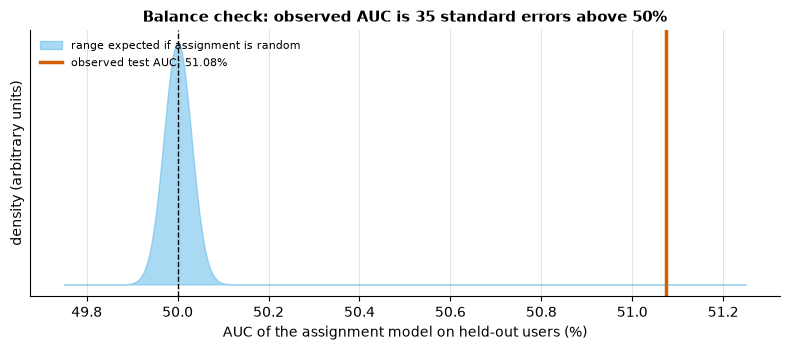

- Observed held-out AUC: **51.08%** (z = 35.2, flagged at the pre-set threshold of p < 0.001).
- On 6,991,697 held-out users, even a tiny departure from 50% is statistically detectable, so the question is how much it matters (sections 3 and 4). The model's predicted chance of being treated ranges (1st to 99th percentile) from 84.5% to 89.7%, against a designed 85% for everyone.
- Largest single-feature standardized difference (notebook 01): 0.049.

In [3]:
bal = effect["balance"]
null_sd = bal["null_se"]
z = (bal["auc"] - 0.5) / null_sd
ctx.check("balance z-score", z, bal["z"], rtol=1e-6)

fig, ax = plt.subplots(figsize=(8, 3.6))
grid = np.linspace(0.4975, 0.5125, 500)
ax.fill_between(
    grid * 100,
    norm.pdf(grid, 0.5, null_sd) / 100,
    color=nb.SKY,
    alpha=0.5,
    label="range expected if assignment is random",
)
ax.axvline(
    bal["auc"] * 100, color=nb.VERMILLION, lw=2.5, label=f"observed test AUC: {pct(bal['auc'], 2)}"
)
ax.axvline(50, color=nb.BLACK, lw=1, ls="--")
ax.set_xlabel("AUC of the assignment model on held-out users (%)")
ax.set_ylabel("density (arbitrary units)")
ax.set_yticks([])
ax.set_title(f"Balance check: observed AUC is {z:.0f} standard errors above 50%")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
ctx.savefig(fig, "validity_balance_auc")

lo99, hi99 = bal["propensity_range_1_99"]
nb.md(
    f"- Observed held-out AUC: **{pct(bal['auc'], 2)}** (z = {z:.1f}, "
    f"{'flagged' if bal['flagged'] else 'not flagged'} at the pre-set threshold of p < {bal['threshold']}).\n"
    f"- On {n_(bal['n_test'])} held-out users, even a tiny departure from 50% is statistically "
    f"detectable, so the question is how much it matters (sections 3 and 4). The model's predicted "
    f"chance of being treated ranges (1st to 99th percentile) from {pct(lo99, 1)} to "
    f"{pct(hi99, 1)}, against a designed {pct(0.85, 0)} for everyone.\n"
    f"- Largest single-feature standardized difference (notebook 01): {design['max_abs_smd']:.3f}."
)

## 3. The lift: raw versus adjusted

- **Raw**: visit rate of treated users minus visit rate of control users.
- **Adjusted (AIPW, doubly robust)**: the same comparison after correcting for the imbalance
  found above, using a propensity model and an outcome model fitted on the train split and
  applied to the test split. It is correct if *either* model is right.

The project's pre-set rule: if the balance check flags, the adjusted estimate is the one that
drives the decision.

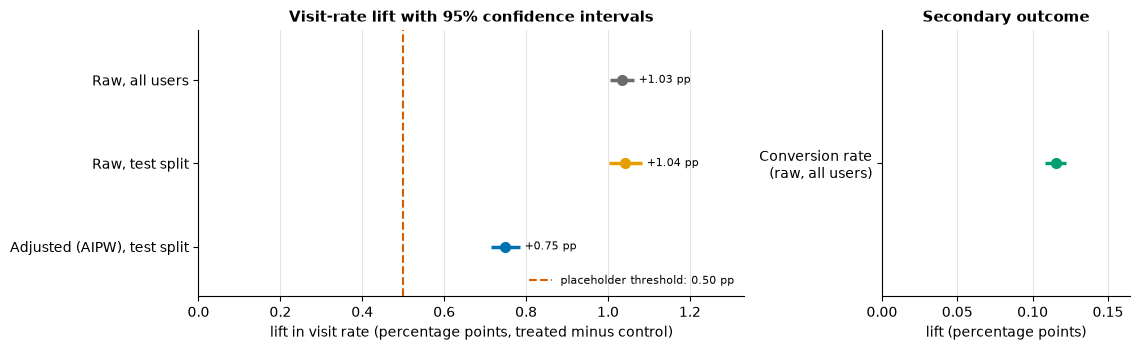

- Raw lift on all users: **+1.03 pp** (+1.01 to +1.06 pp).
- Adjusted lift (test split): **+0.75 pp** (+0.71 to +0.78 pp). Relative to the adjusted control rate of 4.04%, that is +18.6%.
- On the same test split, raw minus adjusted is +0.29 percentage points: that is how much of the raw gap comes from the arms being slightly different kinds of users rather than from the campaign.
- Conversion rate lift (raw, all users): +0.115 pp (+0.108 to +0.122 pp), on a base of 0.194%.
- Primary estimate used for the decision: **adjusted**.

In [4]:
raw_all = EffectEstimate(**effect["visit_raw"])
raw_test = EffectEstimate(**effect["visit_raw_test"])
adj = EffectEstimate(**effect["visit_adjusted"])
conv = EffectEstimate(**effect["conversion"])
primary = adj if effect["primary_basis"] == "adjusted" else raw_all

rows = [
    {
        "label": "Raw, all users",
        "est": raw_all.diff,
        "lo": raw_all.ci_low,
        "hi": raw_all.ci_high,
        "color": nb.GREY,
    },
    {
        "label": "Raw, test split",
        "est": raw_test.diff,
        "lo": raw_test.ci_low,
        "hi": raw_test.ci_high,
        "color": nb.ORANGE,
    },
    {
        "label": "Adjusted (AIPW), test split",
        "est": adj.diff,
        "lo": adj.ci_low,
        "hi": adj.ci_high,
        "color": nb.BLUE,
    },
]
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
nb.forest(a, rows, xlabel="lift in visit rate (percentage points, treated minus control)")
a.axvline(
    effect["practical_threshold"] * 100,
    color=nb.VERMILLION,
    ls="--",
    lw=1.5,
    label=f"placeholder threshold: {effect['practical_threshold'] * 100:.2f} pp",
)
for i, r in enumerate(rows):
    a.text(
        r["hi"] * 100 + 0.012,
        len(rows) - 1 - i,
        f"{r['est'] * 100:+.2f} pp",
        va="center",
        fontsize=8,
    )
a.set_xlim(0, max(r["hi"] for r in rows) * 100 + 0.25)
a.legend(loc="lower right", fontsize=8)
a.set_title("Visit-rate lift with 95% confidence intervals")
nb.forest(
    b,
    [
        {
            "label": "Conversion rate\n(raw, all users)",
            "est": conv.diff,
            "lo": conv.ci_low,
            "hi": conv.ci_high,
            "color": nb.GREEN,
        }
    ],
    xlabel="lift (percentage points)",
)
b.set_title("Secondary outcome")
b.set_xlim(0, conv.ci_high * 100 * 1.35)
fig.tight_layout()
ctx.savefig(fig, "validity_forest_lift")

gap = raw_test.diff - adj.diff
nb.md(
    f"- Raw lift on all users: **{pp(raw_all.diff)}** ({ci_pp(raw_all.ci_low, raw_all.ci_high)}).\n"
    f"- Adjusted lift (test split): **{pp(adj.diff)}** ({ci_pp(adj.ci_low, adj.ci_high)}). "
    f"Relative to the adjusted control rate of {pct(adj.mean_control)}, that is "
    f"{adj.rel_lift:+.1%}.\n"
    f"- On the same test split, raw minus adjusted is {gap * 100:+.2f} percentage points"
    + (
        ": that is how much of the raw gap comes from the arms being slightly different kinds of "
        "users rather than from the campaign.\n"
        if bal["flagged"]
        else ", so the two estimates agree within noise.\n"
    )
    + f"- Conversion rate lift (raw, all users): {pp(conv.diff, 3)} ({ci_pp(conv.ci_low, conv.ci_high, 3)}), "
    f"on a base of {pct(conv.mean_control, 3)}.\n"
    f"- Primary estimate used for the decision: **{effect['primary_basis']}**."
)

## 4. How the decision depends on the threshold

The decision rule compares the confidence interval with a *practical threshold*, the smallest
lift worth acting on:

- whole interval at or above the threshold: **SHIP**
- whole interval below the threshold: **DON'T SHIP**
- interval straddles the threshold: **RUN LONGER**

The Criteo file has no costs, so the threshold in this project is a placeholder
(`expkit/config.py`). The chart shows what the rule says for every threshold from 0 to 1.2 pp.

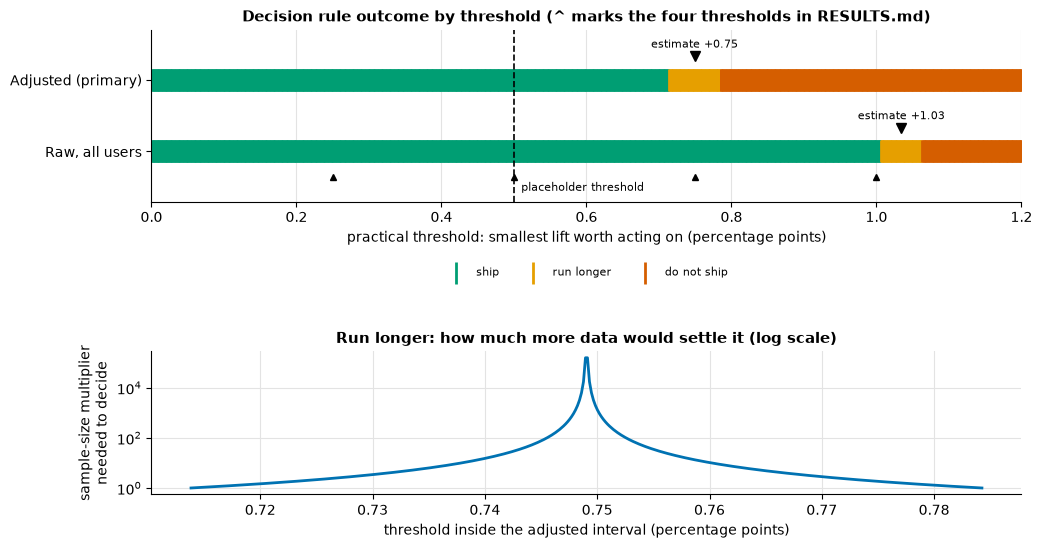

In [5]:
ACTION_LABEL = {"SHIP": "ship", "RUN_LONGER": "run longer", "DONT_SHIP": "do not ship"}
thr_grid = np.linspace(0, 0.012, 1201)
srm_ok = srm_test(obs, config.DESIGN_RATIO_CONTROL_TREATMENT)


def actions(est):
    return np.array([decide(est, t, srm=srm_ok).action for t in thr_grid])


series = [("Adjusted (primary)", adj), ("Raw, all users", raw_all)]
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), gridspec_kw={"height_ratios": [1.2, 1]})
ax = axes[0]
for i, (name, est) in enumerate(series):
    act = actions(est)
    y = len(series) - 1 - i
    for action, color in nb.ACTION_COLORS.items():
        m = act == action
        if m.any():
            ax.scatter(
                thr_grid[m] * 100,
                np.full(m.sum(), y),
                s=260,
                marker="|",
                color=color,
                linewidths=2,
                label=ACTION_LABEL.get(action) if i == 0 else None,
            )
    ax.plot(est.diff * 100, y + 0.33, "v", color=nb.BLACK, ms=7)
    ax.text(est.diff * 100, y + 0.45, f"estimate {est.diff * 100:+.2f}", ha="center", fontsize=8)
ax.axvline(effect["practical_threshold"] * 100, color=nb.BLACK, ls="--", lw=1.2)
ax.text(effect["practical_threshold"] * 100 + 0.01, -0.55, "placeholder threshold", fontsize=8)
for t in config.THRESHOLD_SENSITIVITY:
    ax.plot(t * 100, -0.35, "^", color=nb.BLACK, ms=5)
ax.set_yticks([1, 0])
ax.set_yticklabels([s[0] for s in series])
ax.set_ylim(-0.7, 1.7)
ax.set_xlim(0, 1.2)
ax.set_xlabel("practical threshold: smallest lift worth acting on (percentage points)")
ax.set_title("Decision rule outcome by threshold (^ marks the four thresholds in RESULTS.md)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.32), fontsize=8)

ax = axes[1]
span = np.linspace(adj.ci_low, adj.ci_high, 400)[1:-1]
scale = np.array([required_scale(adj, t) for t in span])
ax.plot(span * 100, scale, color=nb.BLUE, lw=2)
ax.set_yscale("log")
ax.set_xlabel("threshold inside the adjusted interval (percentage points)")
ax.set_ylabel("sample-size multiplier\nneeded to decide")
ax.set_title("Run longer: how much more data would settle it (log scale)")
fig.subplots_adjust(hspace=0.95, left=0.1, right=0.97, top=0.93, bottom=0.1)
ctx.savefig(fig, "validity_threshold_sensitivity")

In [6]:
reported = pd.DataFrame(effect["threshold_sensitivity"])
for r in reported.itertuples():
    assert (
        decide(
            adj if effect["primary_basis"] == "adjusted" else raw_all, r.threshold, srm=srm_ok
        ).action
        == r.action
    )
    assert decide(raw_all, r.threshold, srm=srm_ok).action == r.action_raw
table = pd.DataFrame(
    {
        "threshold": [f"{t * 100:.2f} pp" for t in reported["threshold"]],
        "decision, primary estimate": [ACTION_LABEL[a] for a in reported["action"]],
        "extra data needed": [
            scale_text(None if pd.isna(s) else s) for s in reported["sample_scale"]
        ],
        "decision, raw estimate": [ACTION_LABEL[a] for a in reported["action_raw"]],
    }
)
display(table)
nb.md(
    "The decisions above are recomputed with `expkit.decision.decide` and agree with the table in `docs/RESULTS.md`."
)

,threshold,"decision, primary estimate",extra data needed,"decision, raw estimate"
0,0.25 pp,ship,n/a,ship
1,0.50 pp,ship,n/a,ship
2,0.75 pp,run longer,more than 100x (effectively undecidable),ship
3,1.00 pp,do not ship,n/a,ship


The decisions above are recomputed with `expkit.decision.decide` and agree with the table in `docs/RESULTS.md`.

## Summary

In [7]:
dec = effect["decision"]
by_action: dict[str, list[str]] = {}
for r in reported.itertuples():
    by_action.setdefault(r.action, []).append(f"{r.threshold * 100:.2f}")
flip = "; ".join(f"{ACTION_LABEL[a]} at {', '.join(v)} pp" for a, v in by_action.items())
nb.notes(
    "What this means",
    [
        f"The sample ratio check {'passes' if not srm.flagged else 'FAILS'} (p {('= ' if srm.p_value >= 1e-4 else '')}{srm.p_value:.4g}): "
        f"observed treated share {pct(srm.observed_shares[1], 5)} against 85% designed. "
        + (
            "The counts can be trusted."
            if not srm.flagged
            else "The data cannot be trusted until this is explained."
        ),
        f"A model {'can' if bal['flagged'] else 'cannot'} predict assignment from the features "
        f"(held-out AUC {pct(bal['auc'], 2)}). "
        + (
            "So the adjusted estimate is the headline."
            if effect["primary_basis"] == "adjusted"
            else "So the raw estimate is the headline."
        ),
        f"Estimated lift in visit rate: **{pp(primary.diff)}** (95% CI {ci_pp(primary.ci_low, primary.ci_high)}). "
        f"Raw minus adjusted on the test split is {gap * 100:+.2f} points.",
        f"Decision at the placeholder threshold of {effect['practical_threshold'] * 100:.2f} pp: "
        f"**{ACTION_LABEL[dec['action']]}**. Across the four thresholds: {flip}.",
    ],
)
nb.notes(
    "What is weak",
    [
        "The threshold is an assumption, not data. The recommendation is only as good as that number, "
        "and the threshold chart shows how the call changes as it moves.",
        "SRM only checks arm *sizes*. It cannot see whether the arms contain different kinds of "
        "users, which is why the balance check sits beside it"
        + (" (and it did find a small difference here)." if bal["flagged"] else "."),
        "The adjustment removes only the imbalance that the 12 features reveal. If assignment also "
        "depended on something not in the file, the adjusted lift could still be off.",
        f"This is the effect of being assigned to the campaign. Only {pct(effect['exposed_share_of_treated'])} of treated "
        "users actually saw the ad, and the effect on those who did see it is not estimated here.",
        "The 85% / 15% design ratio comes from the dataset documentation. One experiment, one period: "
        "no checks for novelty, fatigue or seasonality are possible.",
    ],
)

### What this means

- The sample ratio check passes (p = 0.9989): observed treated share 85.00001% against 85% designed. The counts can be trusted.
- A model can predict assignment from the features (held-out AUC 51.08%). So the adjusted estimate is the headline.
- Estimated lift in visit rate: **+0.75 pp** (95% CI +0.71 to +0.78 pp). Raw minus adjusted on the test split is +0.29 points.
- Decision at the placeholder threshold of 0.50 pp: **ship**. Across the four thresholds: ship at 0.25, 0.50 pp; run longer at 0.75 pp; do not ship at 1.00 pp.

### What is weak

- The threshold is an assumption, not data. The recommendation is only as good as that number, and the threshold chart shows how the call changes as it moves.
- SRM only checks arm *sizes*. It cannot see whether the arms contain different kinds of users, which is why the balance check sits beside it (and it did find a small difference here).
- The adjustment removes only the imbalance that the 12 features reveal. If assignment also depended on something not in the file, the adjusted lift could still be off.
- This is the effect of being assigned to the campaign. Only 3.60% of treated users actually saw the ad, and the effect on those who did see it is not estimated here.
- The 85% / 15% design ratio comes from the dataset documentation. One experiment, one period: no checks for novelty, fatigue or seasonality are possible.